# Breast Cancer Classification 

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import warnings 
warnings.filterwarnings('ignore')

## Loading and inspection 

In [2]:
df = pd.read_csv("breast-cancer-wisconsin.data",header=None) #tuve que ocupar None porque mi data no contiene el encabezado 

In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       699 non-null    int64 
 1   1       699 non-null    int64 
 2   2       699 non-null    int64 
 3   3       699 non-null    int64 
 4   4       699 non-null    int64 
 5   5       699 non-null    int64 
 6   6       699 non-null    object
 7   7       699 non-null    int64 
 8   8       699 non-null    int64 
 9   9       699 non-null    int64 
 10  10      699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [5]:
df.shape

(699, 11)

In [6]:
df=df.rename(columns={0:"Sample code number",1:"Clump Thickness",2:"Uniformity of Cell Size",3:"Uniformity of Cell Shape",4:"Marginal Adhesion",5:"Single Epithelial Cell Size",6:"Bare Nuclei",7:"Bland Chromatin",8:"Normal Nucleoli",9:"Mitoses",10:"Class"})

In [7]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


tuve que ejecutar rename ya que mi data venia sin encabezado, tuve que agregar los titulos desde datadiccionary. esto me ayudo a reconocer que cada columna muestra informacion relacionada a los tamañosn, formas y caracteristicas de las celulas. las cuales pueden ser benignas o malignas como muestra mi columna CLass (Target)   

## Missing Values and Data Cleaning 

In [8]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [9]:
df["Sample code number"].unique()

array([ 1000025,  1002945,  1015425,  1016277,  1017023,  1017122,
        1018099,  1018561,  1033078,  1035283,  1036172,  1041801,
        1043999,  1044572,  1047630,  1048672,  1049815,  1050670,
        1050718,  1054590,  1054593,  1056784,  1057013,  1059552,
        1065726,  1066373,  1066979,  1067444,  1070935,  1071760,
        1072179,  1074610,  1075123,  1079304,  1080185,  1081791,
        1084584,  1091262,  1096800,  1099510,  1100524,  1102573,
        1103608,  1103722,  1105257,  1105524,  1106095,  1106829,
        1108370,  1108449,  1110102,  1110503,  1110524,  1111249,
        1112209,  1113038,  1113483,  1113906,  1115282,  1115293,
        1116116,  1116132,  1116192,  1116998,  1117152,  1118039,
        1120559,  1121732,  1121919,  1123061,  1124651,  1125035,
        1126417,  1131294,  1132347,  1133041,  1133136,  1136142,
        1137156,  1143978,  1147044,  1147699,  1147748,  1148278,
        1148873,  1152331,  1155546,  1156272,  1156948,  1157

In [10]:
df["Clump Thickness"].unique()

array([ 5,  3,  6,  4,  8,  1,  2,  7, 10,  9], dtype=int64)

In [11]:
df["Uniformity of Cell Size"].unique()

array([ 1,  4,  8, 10,  2,  3,  7,  5,  6,  9], dtype=int64)

In [12]:
df["Uniformity of Cell Shape"].unique()

array([ 1,  4,  8, 10,  2,  3,  5,  6,  7,  9], dtype=int64)

In [13]:
df["Marginal Adhesion"].unique()

array([ 1,  5,  3,  8, 10,  4,  6,  2,  9,  7], dtype=int64)

In [14]:
df["Single Epithelial Cell Size"].unique()

array([ 2,  7,  3,  1,  6,  4,  5,  8, 10,  9], dtype=int64)

In [15]:
df["Bare Nuclei"].unique()

array(['1', '10', '2', '4', '3', '9', '7', '?', '5', '8', '6'],
      dtype=object)

In [16]:
df["Bare Nuclei"].value_counts()

Bare Nuclei
1     402
10    132
2      30
5      30
3      28
8      21
4      19
?      16
9       9
7       8
6       4
Name: count, dtype: int64

In [17]:
faltantes = df["Bare Nuclei"]=="?" #debo conocer en que rows tengo dato faltante y segun mi feature categorical se si es  Benign: 458 (65.5%) Malignant: 241 (34.5%
df.loc[faltantes,"Class"]

23     4
40     2
139    2
145    2
158    2
164    2
235    2
249    2
275    2
292    4
294    2
297    2
315    2
321    2
411    2
617    2
Name: Class, dtype: int64

#debo comparar la cantidad de casos malignos entre los 699 filas originales y las 683 que quedarian si descarto esa fila. aunque la mayoria sea benigno.*lo que me ayudara a justificar la decision, es cuantos puntos porcentuales cambia la proporcion de malignos* 

In [18]:
df.loc[faltantes, "Class"].value_counts(normalize = True)*100

Class
2    87.5
4    12.5
Name: proportion, dtype: float64

In [19]:
#before 699 filas originales 
df["Class"].value_counts(normalize=True)*100

Class
2    65.522175
4    34.477825
Name: proportion, dtype: float64

In [20]:
df.loc[~faltantes,"Class"].value_counts(normalize=True)*100

Class
2    65.007321
4    34.992679
Name: proportion, dtype: float64

como podemos observar eliminar las filas es una decision razonable, representa solo el 2.3% de los registros y su exclusion cambia muy poco la proporcion de la clase. los casos malignos pasa de 34,48% a 34,99%

In [21]:
df["Bare Nuclei"] = df ["Bare Nuclei"].replace("?", np.nan)

In [22]:
df = df.dropna()
df.count()

Sample code number             683
Clump Thickness                683
Uniformity of Cell Size        683
Uniformity of Cell Shape       683
Marginal Adhesion              683
Single Epithelial Cell Size    683
Bare Nuclei                    683
Bland Chromatin                683
Normal Nucleoli                683
Mitoses                        683
Class                          683
dtype: int64

In [23]:
df["Bare Nuclei"] = df["Bare Nuclei"].astype("int64")

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 683 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Sample code number           683 non-null    int64
 1   Clump Thickness              683 non-null    int64
 2   Uniformity of Cell Size      683 non-null    int64
 3   Uniformity of Cell Shape     683 non-null    int64
 4   Marginal Adhesion            683 non-null    int64
 5   Single Epithelial Cell Size  683 non-null    int64
 6   Bare Nuclei                  683 non-null    int64
 7   Bland Chromatin              683 non-null    int64
 8   Normal Nucleoli              683 non-null    int64
 9   Mitoses                      683 non-null    int64
 10  Class                        683 non-null    int64
dtypes: int64(11)
memory usage: 64.0 KB


In [25]:
df.isnull().sum()

Sample code number             0
Clump Thickness                0
Uniformity of Cell Size        0
Uniformity of Cell Shape       0
Marginal Adhesion              0
Single Epithelial Cell Size    0
Bare Nuclei                    0
Bland Chromatin                0
Normal Nucleoli                0
Mitoses                        0
Class                          0
dtype: int64

In [26]:
df.shape

(683, 11)

luego de analizar la data decidi eliminar las filas de los datos faltantes para trabajar 

In [27]:
df["Bare Nuclei"].unique()

array([ 1, 10,  2,  4,  3,  9,  7,  5,  8,  6], dtype=int64)

In [28]:
df["Bland Chromatin"].unique()

array([ 3,  9,  1,  2,  4,  5,  7,  8,  6, 10], dtype=int64)

In [29]:
df["Normal Nucleoli"].unique()

array([ 1,  2,  7,  4,  5,  3, 10,  6,  9,  8], dtype=int64)

In [30]:
df["Mitoses"].unique()

array([ 1,  5,  4,  2,  3,  7, 10,  8,  6], dtype=int64)

In [31]:
df["Class"].unique()

array([2, 4], dtype=int64)

In [32]:
df.head()

,Sample code number,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


## Feature and Target Selection 

In [33]:
df_new =df.drop(columns=["Sample code number"])

In [34]:
df_new.head()

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,1,1,1,2,1,3,1,1,2
1,5,4,4,5,7,10,3,2,1,2
2,3,1,1,1,2,2,3,1,1,2
3,6,8,8,1,3,4,3,7,1,2
4,4,1,1,3,2,1,3,1,1,2


In [35]:
# Import train_test_split function
from sklearn.model_selection import train_test_split

X = df_new[['Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion',"Single Epithelial Cell Size","Bare Nuclei","Bland Chromatin","Normal Nucleoli","Mitoses"]]  # Features
y = df['Class'] # 

Exclui Sample Code number de los predictores porque es un identificador de la muestra y no mide nunguna caracteristica celular. use class como variable objetico (y), ya que indica si la muestra es benigna o maligna. Las nueve caracteristicas celulares quedaron en X como predictores.

## Preliminary comparison of five Classifiers 

In [36]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 5)

In [37]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state = 42),
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
    "Logistic Regression": LogisticRegression(max_iter = 1000, random_state = 42),
    "Support Vector Machine": SVC(kernel='linear', random_state = 42)
}

In [38]:
# Train and evaluate ML model classifiers for breast cancer Wisconsin dataset 
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [39]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)    

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.982456   0.983333  0.982456  0.982564
1           Decision Tree  0.941520   0.942292  0.941520  0.941766
2           Random Forest  0.970760   0.973118  0.970760  0.971047
3     Logistic Regression  0.988304   0.988304  0.988304  0.988304
4  Support Vector Machine  0.970760   0.971772  0.970760  0.970940


 ## Five-fold cross-validation on the training set

In [40]:
# Five-fold cross-validation on the training set
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.960918
1           Decision Tree          0.951190
2           Random Forest          0.970683
3     Logistic Regression          0.955054
4  Support Vector Machine          0.958957


## Random Forest Test - Set Evaluation

### 5% Test Split

In [47]:
print(X.shape,X.columns.tolist())

(683, 9) ['Clump Thickness', 'Uniformity of Cell Size', 'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin', 'Normal Nucleoli', 'Mitoses']


In [48]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.05,  random_state = 5) # 95% training and 5% testing

In [49]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a random forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 100,random_state = 42)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [50]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 1.0
Accuracy: 1.00


In [51]:
# NEW SAMPLE prediction (correct way)
new_sample = [[1,2,3,4,5,6,7,8,9]]

prediction = clf_RF.predict(new_sample)              # predict class
proba = clf_RF.predict_proba(new_sample)             # predict probabilities

# Class names
print("Predicted Class:", prediction[0])

Predicted Class: 4


In [52]:
print("Confidence:", round(max(proba[0]), 3))

Confidence: 0.62


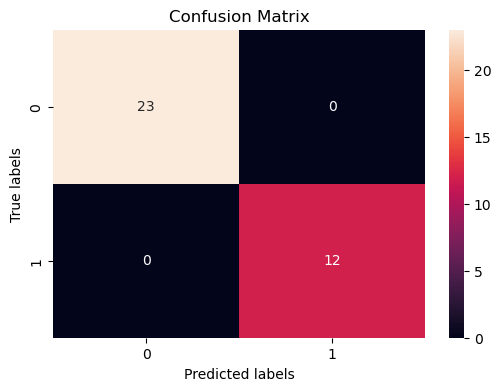

Classification Report:
              precision    recall  f1-score   support

           2       1.00      1.00      1.00        23
           4       1.00      1.00      1.00        12

    accuracy                           1.00        35
   macro avg       1.00      1.00      1.00        35
weighted avg       1.00      1.00      1.00        35



In [53]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf_RF.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

como se puede observar en el primer ejemplos la diagonal nos muestra que se realizaron 35 aciertos de 35 muestras clasifico correctamente las 23 benignas y 12 malignas. todo esto en solo 35 muestras de prueba  

### 15% Test Split

In [54]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15,  random_state = 5) # 85% training and 15% test

In [55]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a random forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 100, random_state = 42)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [56]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 1.0
Accuracy: 1.00


In [57]:
# NEW SAMPLE prediction (correct way)
new_sample = [[1,2,3,4,5,6,7,8,9]]

prediction = clf_RF.predict(new_sample)              # predict class
proba = clf_RF.predict_proba(new_sample)             # predict probabilities

# Class names
print("Predicted Class:", prediction[0])

Predicted Class: 4


In [58]:
print("Confidence:", round(max(proba[0]), 3))

Confidence: 0.56


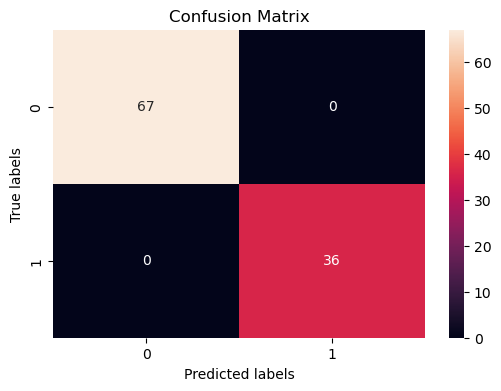

Classification Report:
              precision    recall  f1-score   support

           2       1.00      1.00      1.00        67
           4       1.00      1.00      1.00        36

    accuracy                           1.00       103
   macro avg       1.00      1.00      1.00       103
weighted avg       1.00      1.00      1.00       103



In [59]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf_RF.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

en la confusion matrix de 15% hemos conseguido un 100% correcto en el conjunto mostrando 103 muestas 67 para benigna y 36 malignas sin errores

### 25% Test Split

In [60]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25,  random_state = 5) # 75% training and 25% test

In [61]:
#Import Random Forest Model
from sklearn.ensemble import RandomForestClassifier

#Create a random forest Classifier
clf_RF = RandomForestClassifier(n_estimators = 100, random_state = 42)

#Train the model using the training sets y_pred=clf.predict(X_test)
clf_RF.fit(X_train, y_train)

y_pred = clf_RF.predict(X_test)

In [62]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

# Rounded upto 2 decimal places
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_pred)) )

Accuracy: 0.9707602339181286
Accuracy: 0.97


In [63]:
# NEW SAMPLE prediction (correct way)
new_sample = [[1,2,3,4,5,6,7,8,9]]

prediction = clf_RF.predict(new_sample)              # predict class
proba = clf_RF.predict_proba(new_sample)             # predict probabilities

# Class names
print("Predicted Class:", prediction[0])

Predicted Class: 4


In [64]:
print("Confidence:", round(max(proba[0]), 3))

Confidence: 0.62


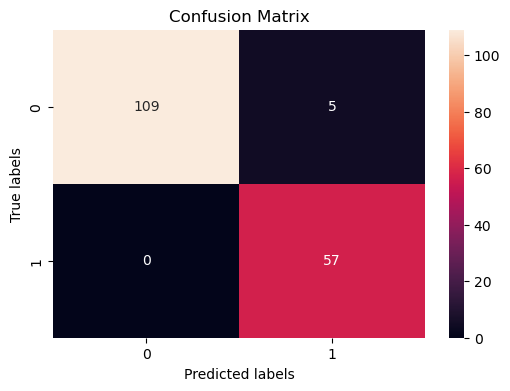

Classification Report:
              precision    recall  f1-score   support

           2       1.00      0.96      0.98       114
           4       0.92      1.00      0.96        57

    accuracy                           0.97       171
   macro avg       0.96      0.98      0.97       171
weighted avg       0.97      0.97      0.97       171



In [65]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Predict by using an object classifier 'clf'
y_predict = clf_RF.predict(X_test)

# Calculate cm by using a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Plot confusion matrix with integers using seaborn heatmap
plt.figure(figsize = (6, 4))
sns.heatmap(cm, annot = True, fmt = 'd')        # 'd' stands for integer format
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

# Generate classification report
report = classification_report(y_test, y_predict)
print("Classification Report:")
print(report)

## K-Nearest Neighbors test - Set Evaluation

## Kkn - 5% Test Split

In [66]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size= 0.05, random_state=5)

In [67]:
from sklearn.neighbors import KNeighborsClassifier
kNN = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
kNN.fit(X_train,y_train)

KNeighborsClassifier()

<Axes: >

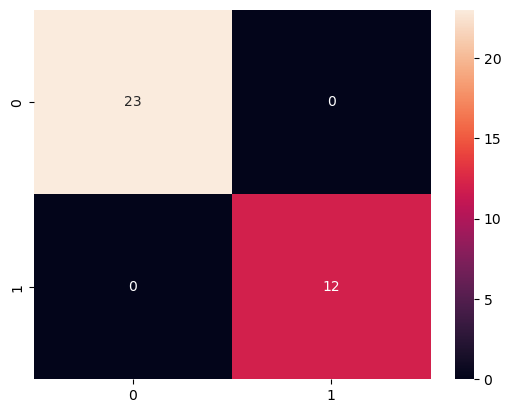

In [68]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Call a method predict by using an object classifier 'cls_svm'
y_predict = kNN.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

In [69]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy, how often is the classifier correct?
print( "Accuracy: {:.2f}".format(metrics.accuracy_score(y_test, y_predict)) )

Accuracy: 1.00


In [70]:
from sklearn.metrics import classification_report

# Display the classification report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           2       1.00      1.00      1.00        23
           4       1.00      1.00      1.00        12

    accuracy                           1.00        35
   macro avg       1.00      1.00      1.00        35
weighted avg       1.00      1.00      1.00        35



## Kkn - 15% Test Split

In [71]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size= 0.15, random_state=5)

In [72]:
from sklearn.neighbors import KNeighborsClassifier
kNN = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
kNN.fit(X_train,y_train)

KNeighborsClassifier()

<Axes: >

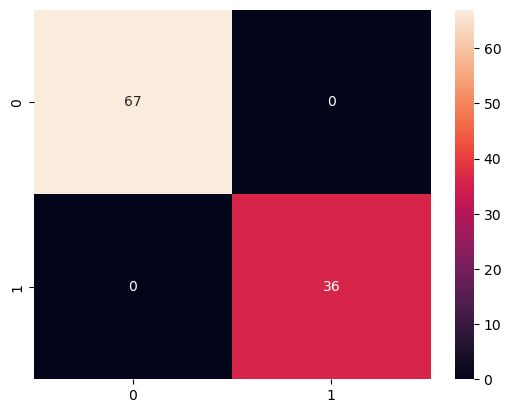

In [73]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Call a method predict by using an object classifier 'cls_svm'
y_predict = kNN.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

## Kkn - 25% Test Split

In [108]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test =train_test_split(X,y,test_size= 0.25, random_state=5)

In [109]:
from sklearn.neighbors import KNeighborsClassifier
kNN = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)
kNN.fit(X_train,y_train)

KNeighborsClassifier()

<Axes: >

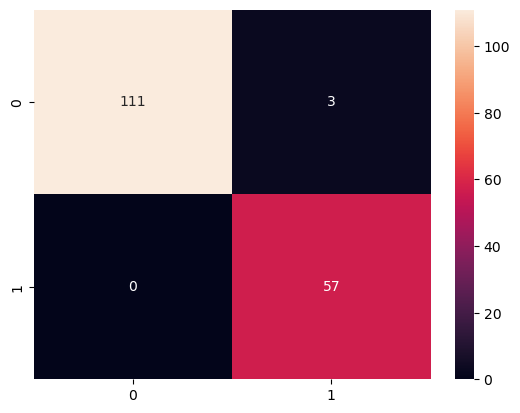

In [111]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Call a method predict by using an object classifier 'cls_svm'
y_predict = kNN.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True, fmt="d")

## Cross-Validation Across the Three Test Splits 

In [104]:
models = {"Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
        "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
}
cv_results= []
for test_size in [0.05, 0.15, 0.25]:
    X_train_cv, _,y_train_cv, _ = train_test_split(X, y, test_size = test_size, random_state = 5)

    for name, model in models.items():
        cv_scores = cross_val_score(
            model, X_train_cv, y_train_cv, cv=5, scoring = "accuracy")
        cv_results.append({
            "test Split":f"{test_size:.0%}",
            "Model":name,
            "Mean CV Accuracy (%)": round(cv_scores.mean() * 100, 2),
            "CV Accuracy Std (pp)": round(cv_scores.std()* 100, 2),
        })

cv_by_split_df = pd.DataFrame(cv_results)
cv_by_split_df
         
                                            

,test Split,Model,Mean CV Accuracy (%),CV Accuracy Std (pp)
0,5%,Random Forest,96.91,1.75
1,5%,k-Nearest Neighbors,96.30,1.41
2,15%,Random Forest,96.55,1.44
3,15%,k-Nearest Neighbors,95.86,1.01
4,25%,Random Forest,97.07,1.63
5,25%,k-Nearest Neighbors,96.09,2.30


### Mean Cross-Validation Accuracy by Test Split 

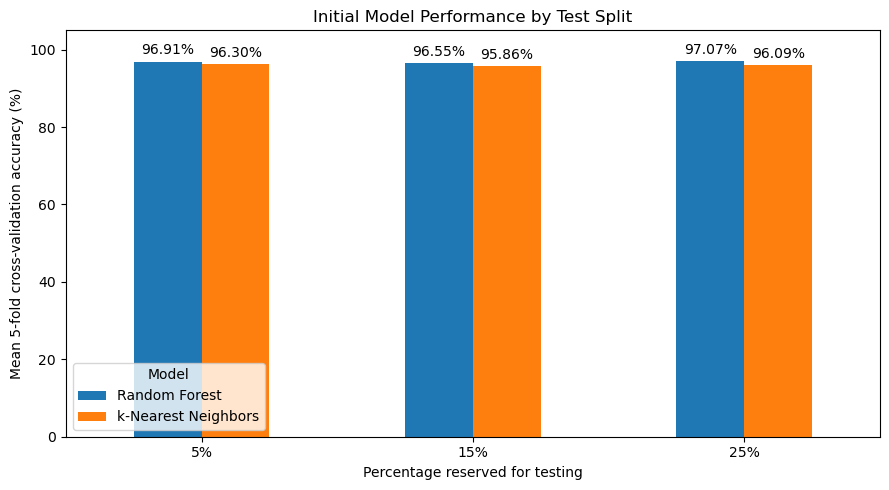

In [100]:
import matplotlib.pyplot as plt #prompt

initial_accuracy = cv_by_split_df.pivot(
    index="test Split",
    columns="Model",
    values="Mean CV Accuracy (%)",
).reindex(["5%", "15%", "25%"])

ax = initial_accuracy.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Initial Model Performance by Test Split")
ax.set_xlabel("Percentage reserved for testing")
ax.set_ylabel("Mean 5-fold cross-validation accuracy (%)")
ax.set_ylim(0, 105)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

### Training vs. Validation Accuracy (*75 / 25* Split)

In [82]:
from sklearn.model_selection import cross_validate, train_test_split #prompt 

X_train_25, _, y_train_25, _ = train_test_split(
    X, y, test_size=0.25, random_state=5
)

fit_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train_25,
        y_train_25,
        cv=5,
        scoring="accuracy",
        return_train_score=True,
    )

    train_mean = scores["train_score"].mean() * 100
    validation_mean = scores["test_score"].mean() * 100

    fit_results.append({
        "Model": name,
        "Training Accuracy (%)": train_mean,
        "Validation Accuracy (%)": validation_mean,
        "Gap (pp)": train_mean - validation_mean,
    })

fit_df = pd.DataFrame(fit_results)
fit_df.round(2)

,Model,Training Accuracy (%),Validation Accuracy (%),Gap (pp)
0,Random Forest,100.00,97.07,2.93
1,k-Nearest Neighbors,97.66,96.09,1.56


## Baseline Model Comparison on the Test Sets 

### 5% Test Split

In [83]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
     "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
}

In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=5
)

In [85]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [86]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision  Recall  F1 Score
0        Random Forest       1.0        1.0     1.0       1.0
1  k-Nearest Neighbors       1.0        1.0     1.0       1.0


### 15% test split

In [87]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
     "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
}

In [88]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=5
)

In [89]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [90]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision  Recall  F1 Score
0        Random Forest       1.0        1.0     1.0       1.0
1  k-Nearest Neighbors       1.0        1.0     1.0       1.0


### 25% test split

In [91]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators = 100, random_state = 42),
   "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
}

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

In [93]:
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [94]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)   

Model Performance Metrics on Test Set:
                 Model  Accuracy  Precision    Recall  F1 Score
0        Random Forest  0.970760   0.973118  0.970760  0.971047
1  k-Nearest Neighbors  0.982456   0.983333  0.982456  0.982564


## Hyperparameter Tuning With GridSearchCV

In [95]:
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}
    
    

In [96]:
param_grids = {
    "k-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9, 11],
    },
    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 5 , 10, 20, 30],
       
    }
}

In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

In [98]:
# Apply GridSearchCV for each classifier and evaluate performance metric scores
results = []
for name, classifier in classifiers.items():
    print(f"Running GridSearchCV for {name}...")
    grid_search = GridSearchCV(estimator=classifier, param_grid=param_grids[name], cv = 5, n_jobs = -1, verbose = 2)
    grid_search.fit(X_train, y_train)
    
    # Best model from grid search
    best_model = grid_search.best_estimator_
    
    # Predict on the test set with the best model
    y_pred = best_model.predict(X_test)
    
    from sklearn.metrics import confusion_matrix
    print(name)
    print(confusion_matrix(y_test, y_pred, labels= [2, 4]))

    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score, grid_search.best_params_, grid_search.best_score_])

Running GridSearchCV for k-Nearest Neighbors...
Fitting 5 folds for each of 5 candidates, totalling 25 fits
k-Nearest Neighbors
[[111   3]
 [  1  56]]
Running GridSearchCV for Random Forest...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Random Forest
[[109   5]
 [  0  57]]


como podemos observar en el GridSearchCV la medicion por medio de K-Nearest neighbors fue 111 de 114 muestras benignas clasificadas correctamente y 3 benignas clasificadas como malignas, y 1 maligna clasificada como benigna. en cambio para random forest se generaron 109 de 114 muestras benignas clasificadas correctamente y 5 benignas clasificadas como malignas, y mas mediciones de malignas no tuvieron error en el calculo 

In [99]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Test Accuracy", "Precision", "Recall", "F1 Score", "Best Parameters", "Best Mean CV Accuracy"])
print("Model Performance Metrics on Test Set after GridSearchCV:")
print(results_df)

Model Performance Metrics on Test Set after GridSearchCV:
                 Model  Test Accuracy  Precision    Recall  F1 Score  \
0  k-Nearest Neighbors       0.976608   0.977098  0.976608  0.976706   
1        Random Forest       0.970760   0.973118  0.970760  0.971047   

                        Best Parameters  Best Mean CV Accuracy  
0                    {'n_neighbors': 9}               0.966819  
1  {'max_depth': 5, 'n_estimators': 50}               0.974605  


para este informe ajuste ambos modelos con el 75% de entrenamiento y use el 25% reservado para evaluar la accuracy de prueba

### Validation and Test Accuracy After Tuning 

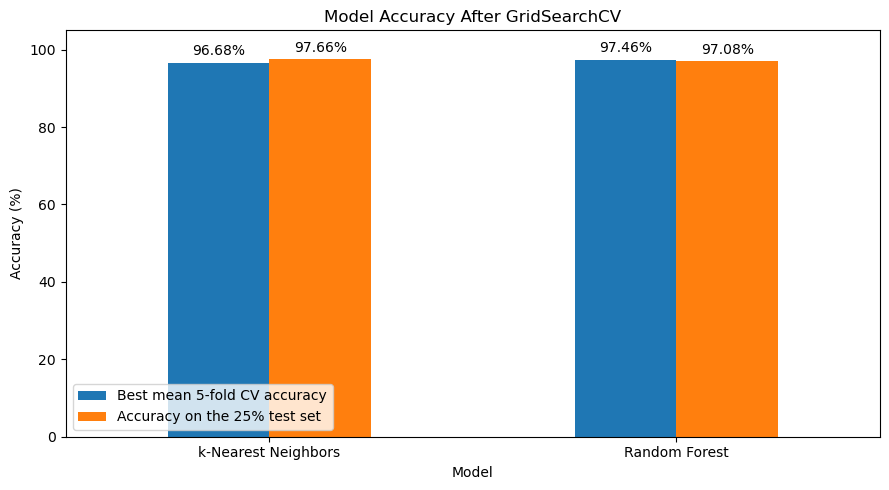

In [101]:
import matplotlib.pyplot as plt #prompt 

accuracy_comparison = results_df.set_index("Model")[
    ["Best Mean CV Accuracy", "Test Accuracy"]
].mul(100)

accuracy_comparison.columns = [
    "Best mean 5-fold CV accuracy",
    "Accuracy on the 25% test set",
]

ax = accuracy_comparison.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Model Accuracy After GridSearchCV")
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()

## Effect of Bare Nuclei on Random Forest Accuracy

In [102]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=5
)

In [103]:
model = RandomForestClassifier(n_estimators=100, random_state=42) #Prompt 

accuracy_with = cross_val_score(
    model, X_train, y_train, cv=5, scoring="accuracy"
).mean()

accuracy_without = cross_val_score(
    model, X_train.drop(columns=["Bare Nuclei"]), y_train,
    cv=5, scoring="accuracy"
).mean()

print(f"with Bare Nuclei: {accuracy_with:.2%}")
print(f"without Bare Nuclei: {accuracy_without:.2%}")
print(f"Difference (with − without): {(accuracy_with - accuracy_without) * 100:.2f} percentage points")

with Bare Nuclei: 97.07%
without Bare Nuclei: 96.10%
Difference (with − without): 0.97 percentage points
